# Setup

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

!rm -rf DL4CM # clear up dir if any
!git clone https://github.com/ti55987/DL4CM.git

%cd DL4CM

Mounted at /content/gdrive
Cloning into 'DL4CM'...
remote: Enumerating objects: 254, done.
remote: Counting objects: 100% (254/254), done.
remote: Compressing objects: 100% (178/178), done.
remote: Total 254 (delta 145), reused 177 (delta 68), pack-reused 0 (from 0)
Receiving objects: 100% (254/254), 6.50 MiB | 25.52 MiB/s, done.
Resolving deltas: 100% (145/145), done.
/content/DL4CM


In [2]:
import logging
import time
import math
import os

import tensorflow as tf
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotnine as gg
from sklearn.utils import shuffle
import seaborn as sns

from utils.feature_utils import (
    get_labels,
    get_condition_aware_labels,
    get_block_features,
    ParameterNormalizer,
    normalize_val_labels,
    normalize_train_labels,
    get_iter_acc_without_switches,
    get_iter_acc_with_switches,
    extract_features_blockless,
)

# Read your simulation data

In [3]:
DRIVE_DIR = '/content/gdrive/Shareddrives/DLCCM/blocks'
task = 'RLF-6S3A'
DATA_DIR = f'/content/gdrive/MyDrive/Colab Notebooks/data/{task}'
RESULT_DIR = f'{DRIVE_DIR}/results/{task}'
N_TRAIN_AGENT, N_TEST_AGENT = 9000, 500
num_blocks = 12
num_trials_per_block = 6*13
beta_multiplier = 20

suffix = 'rlf'
prefix = f'rand_500seqs_{N_TRAIN_AGENT}a_{num_blocks}b_{num_trials_per_block}t_{suffix}'
training_data = pd.read_csv(f'{DATA_DIR}/{prefix}.csv')
if 'beta' in training_data.columns:
  training_data['beta'] = training_data['beta']/beta_multiplier

test_data = pd.read_csv(f'{DATA_DIR}/rand500_st11_{N_TEST_AGENT}a_{num_blocks}b_{num_trials_per_block}t_{suffix}.csv')
if 'beta' in test_data.columns:
  test_data['beta'] = test_data['beta']/beta_multiplier

In [4]:
# @title spilt dataset
limit = 3000
sampled_agents = np.random.choice(training_data['agentid'].unique(), size=limit, replace=False)
# Filter your dataframe to only include those agents
sample_data = training_data[training_data['agentid'].isin(sampled_agents)].copy()

N_TRAIN_AGENT = len(sample_data.agentid.unique())
val_agent_ids = np.random.choice(sample_data.agentid.nunique(), int(N_TRAIN_AGENT*0.1), replace=False)
training_data = sample_data[sample_data.trials < num_trials_per_block]
val_data = sample_data[sample_data.agentid.isin(val_agent_ids)]
training_data = sample_data[~sample_data.agentid.isin(val_agent_ids)]

# Process data

In [5]:
# @title Process training labels

# (TODO) add your own model parameters.
shared = ['bias', 'phi', 'stickiness', 'eps'] #['beta', 'alpha', 'phi', 'stickiness']
train_labels = get_condition_aware_labels(training_data, shared, [])
val_labels = get_condition_aware_labels(val_data, shared, [])

normalized_train_labels, name_to_scaler = normalize_train_labels(train_labels)
normalized_val_labels =  normalize_val_labels(val_labels, name_to_scaler)
normalized_val_labels.shape

(103, 4)

In [6]:
# @title get iteration features
from utils.feature_utils import (
    get_iter_acc_without_switches,
    get_iter_acc_with_switches,
    extract_features_blockless,
)

# Extract features in RL based models. Skip this part if it is not relevant to your task or model.
has_switches = (test_data.isswitch.nunique() == 2)
td_iter, vd_iter = training_data, val_data
if 'stim_iter' not in training_data.columns:
  td_iter = get_iter_acc_with_switches(training_data) if has_switches else get_iter_acc_without_switches(training_data)
  vd_iter = get_iter_acc_with_switches(val_data) if has_switches else get_iter_acc_without_switches(val_data)

if has_switches:
  td_iter.loc[td_iter.trials == 0, 'isswitch'] = 1
  vd_iter.loc[vd_iter.trials == 0, 'isswitch'] = 1
else:
  td_iter['isswitch'] = td_iter['trials'].apply(lambda x: 1 if x == 0 else 0)
  vd_iter['isswitch'] = vd_iter['trials'].apply(lambda x: 1 if x == 0 else 0)


td_iter['prev_action'] = training_data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()
vd_iter['prev_action'] = val_data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()

/tmp/ipykernel_19210/871939429.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_19210/871939429.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_19210/871939429.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_19210/8

In [7]:
# @title extract blockless features

sorted_col = ['agentid', 'block_no', 'stimuli']
td_iter_order = td_iter.sort_values(sorted_col)
vd_iter_order = vd_iter.sort_values(sorted_col)

feature_list = ['actions', 'rewards', 'stim_iter', 'isswitch', 'prev_action', 'delay_since_last_stimuli']
train_features = extract_features_blockless(td_iter_order, feature_list, [])
val_features   = extract_features_blockless(vd_iter_order, feature_list, [])

print("Train features shape:", train_features.shape)
print("Val features shape:", val_features.shape)


Train features shape: (2897, 936, 6)
Val features shape: (103, 936, 6)


In [8]:
#@title shuffle data
from sklearn.utils import shuffle

train_features, normalized_train_labels = shuffle(train_features, normalized_train_labels, random_state=0)
val_features, normalized_val_labels = shuffle(val_features, normalized_val_labels, random_state=0)
print(train_features.shape, val_features.shape, normalized_val_labels.shape)

(2897, 936, 6) (103, 936, 6) (103, 4)


# Model training

In [9]:
# @title Original GRU definition

from tensorflow.keras import layers
from keras.callbacks import EarlyStopping

from tensorflow.keras.layers import (
    Dense,
    Input,
    Dropout,
    Bidirectional,
    GRU,
)
from tensorflow import keras
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(33)
tf.config.experimental.enable_op_determinism()


def create_gru_model(
    feature_dim: int,
    output_dims: int,
    units: int=70, dropout: float=0.2,
    dropout1: float=0.2, dropout2: float=0.1,
    learning_rate: float=3e-4):
    activation_func = 'relu'

    encoder_inputs = layers.Input(shape=(None, feature_dim))
    encoder = GRU(units, return_state=False, return_sequences=False)
    encoder_outputs = encoder(encoder_inputs)
    encoder_outputs = Dropout(dropout)(encoder_outputs) #Dropout(dropout)(encoder_outputs)

    # Dense layers
    outputs = Dense(int(units/2), activation='relu')(encoder_outputs)
    outputs = Dropout(dropout1)(outputs)
    outputs = Dense(int(units/4), activation='relu')(outputs)
    outputs = Dropout(dropout2)(outputs)
    outputs = Dense(output_dims, activation='linear')(outputs)

    best_model = keras.Model(encoder_inputs, outputs)

    optimizer = Adam(learning_rate=learning_rate)
    best_model.compile(loss='mse', optimizer=optimizer)
    return best_model

def get_gru_model(parms):
    return create_gru_model(
        parms['feature_dim'],
        parms['output_dims'],
        parms['units'],
        parms['dropout'],
        parms['dropout1'],
        parms['dropout2'],
        parms['learning_rate'])

In [10]:
# @title GRU
# earch({'batch_size': 128, 'dropout': 0.05469810926102504, 'dropout1': 0.03270538551855236, 'dropout2': 0.020741906361950876, 'epochs': 35, 'feature_dim': 6, 'learning_rate': 0.002494216656437813, 'output_dims': 4, 'units': 512})
# SCORE: 0.24846 at epoch 20
batch_size = 128
units = 96
dropout = 0.065
dropout1 = 0.1929
dropout2 = 0.113
learning_rate = 0.002

tf.keras.utils.set_random_seed(11)
identifier = f'{prefix}_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}'
best_model = create_gru_model(
    feature_dim=train_features.shape[-1],
    output_dims=normalized_train_labels.shape[-1],
    units=units,
    dropout=dropout,
    dropout1=dropout1,
    dropout2=dropout2,
    learning_rate=learning_rate,
)

print(identifier)

rand_500seqs_9000a_12b_78t_rlf_B128_U96_D0.065_D0.1929_D0.113_0.002


In [11]:
callbacks = [EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)]

start = time.time()
history = best_model.fit(
      train_features,
      normalized_train_labels,
      epochs=600,
      batch_size=batch_size,
      callbacks=callbacks,
      validation_data = (val_features, normalized_val_labels),
      verbose=2)

end = time.time()

Epoch 1/600
23/23 - 5s - 210ms/step - loss: 0.5528 - val_loss: 0.5846
Epoch 2/600
23/23 - 1s - 38ms/step - loss: 0.5031 - val_loss: 0.5855
Epoch 3/600
23/23 - 1s - 38ms/step - loss: 0.4983 - val_loss: 0.5845
Epoch 4/600
23/23 - 1s - 38ms/step - loss: 0.4940 - val_loss: 0.5807
Epoch 5/600
23/23 - 1s - 40ms/step - loss: 0.4771 - val_loss: 0.5494
Epoch 6/600
23/23 - 1s - 43ms/step - loss: 0.4405 - val_loss: 0.5073
Epoch 7/600
23/23 - 1s - 39ms/step - loss: 0.4737 - val_loss: 0.5754
Epoch 8/600
23/23 - 1s - 39ms/step - loss: 0.4666 - val_loss: 0.5426
Epoch 9/600
23/23 - 1s - 38ms/step - loss: 0.4179 - val_loss: 0.4641
Epoch 10/600
23/23 - 1s - 38ms/step - loss: 0.3703 - val_loss: 0.4091
Epoch 11/600
23/23 - 1s - 38ms/step - loss: 0.3523 - val_loss: 0.3892
Epoch 12/600
23/23 - 1s - 38ms/step - loss: 0.3384 - val_loss: 0.3692
Epoch 13/600
23/23 - 1s - 38ms/step - loss: 0.3159 - val_loss: 0.3327
Epoch 14/600
23/23 - 1s - 38ms/step - loss: 0.2910 - val_loss: 0.2700
Epoch 15/600
23/23 - 1s - 38

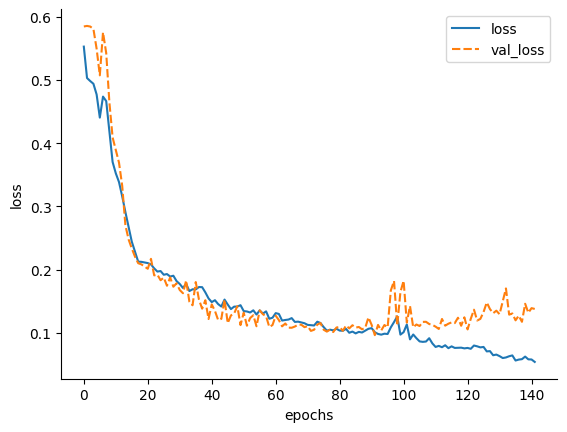

In [12]:
result = pd.DataFrame(history.history)
ax = sns.lineplot(result)
ax.set_xlabel('epochs')
ax.set_ylabel('loss')
sns.despine()
result.to_csv(f'{RESULT_DIR}/{identifier}_loss_history.csv')
plt.savefig(f'{RESULT_DIR}/{identifier}.png')
#best_model.save(f'{RESULT_DIR}/{identifier}_model.keras')

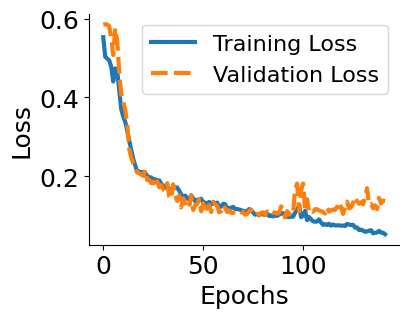

In [21]:
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
ax = sns.lineplot(result, ax=ax, linewidth=3)
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

# Get current legend handles and labels
handles, labels = ax.get_legend_handles_labels()

# Map original labels to new labels
new_labels = []
for label in labels:
    if label == 'loss':
        new_labels.append('Training Loss')
    elif label == 'val_loss':
        new_labels.append('Validation Loss')
    else:
        new_labels.append(label)

# Set the new legend
ax.legend(handles, new_labels, fontsize=16)

sns.despine()

FIG_DIR = f'{DRIVE_DIR}/figures'
fig.savefig(
    f"{FIG_DIR}/loss_history.png",
    dpi=600,
    bbox_inches="tight",
)

# Model Evaluation

In [ ]:
# loading previously trained models if any...
# model_name = f'{RESULT_DIR}/model_name.keras'
# best_model = tf.keras.models.load_model(model_name)

In [ ]:
short_test_data = test_data[test_data.agentid < 500]
has_switches = (test_data.isswitch.nunique() == 2)
test_iter = short_test_data
if 'stim_iter' not in short_test_data.columns:
  test_iter = get_iter_acc_with_switches(short_test_data) if has_switches else get_iter_acc_without_switches(short_test_data)

test_iter['isswitch'] = test_iter['trials'].apply(lambda x: 1 if x == 0 else 0)
test_iter['prev_action'] = test_data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()

test_iter_order = test_iter.sort_values(by=sorted_col)
test_features = extract_features_blockless(test_iter_order, feature_list, [])

true_labels = get_condition_aware_labels(short_test_data, shared, [])

test_features.shape

(500, 936, 6)

In [ ]:
from utils.feature_utils import (
    get_recovered_parameters,
    recover_parameter,
)


predicted = best_model.predict(test_features)
result = get_recovered_parameters(name_to_scaler, true_labels, predicted)
if ('true_beta' in result.columns) and (result.true_beta.max() > 1):
  result['true_beta'] = result['true_beta']/beta_multiplier
  result['dl_beta'] = result['dl_beta']/beta_multiplier

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step


In [ ]:
result.to_csv(f'{RESULT_DIR}/st11_{identifier}_param_pred.csv')

Text(0.5, 1.01, 'train on 9000 agent 12 block 78 trial,test on 500 agent')

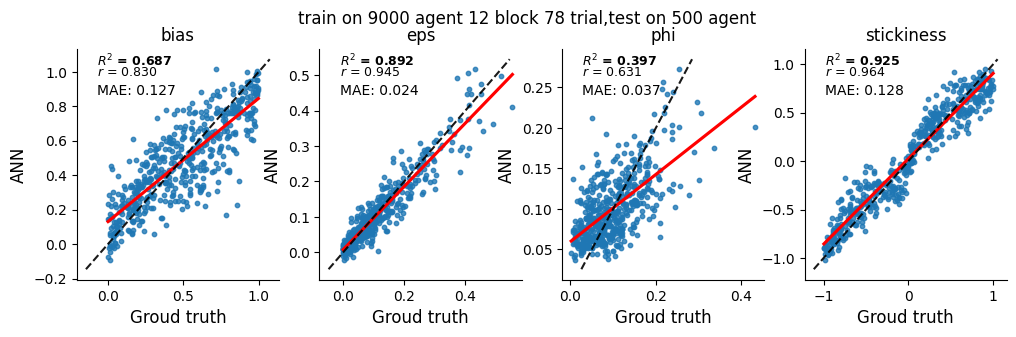

In [ ]:
from sklearn.metrics import r2_score
from utils.evaluation_utils import (
    add_corr_scores,
)
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

params = list(true_labels.keys())
n_row, n_col = 1, len(params)
f, axarr = plt.subplots(n_row, n_col, figsize=(3 * n_col, 3 * n_row))

for i, p in enumerate(np.sort(params)):
  true_l, dl_l = f"true_{p}", f"dl_{p}"

  # Apply log transformation to alpha if it's the current parameter
  if p in []:#'
    min_pv = np.min(result[dl_l])
    if min_pv < 0:
      noise = -np.min(min_pv)+0.00001
    else:
      noise = 0

    true_values = -np.log(result[true_l])
    predicted_values = -np.log(result[dl_l]+noise)
    ax = sns.regplot(
        x=true_values, y=predicted_values, ax=axarr.flat[i],
        ci=None, scatter_kws=dict(s=10), line_kws=dict(color="r"))
    ax = add_corr_scores(ax, true_values, predicted_values)
  else:
    ax = sns.regplot(
        data=result, ci=None, x=true_l, y=dl_l, ax=axarr.flat[i],
        scatter_kws=dict(s=10), line_kws=dict(color="r"))
    ax = add_corr_scores(ax, result[true_l], result[dl_l])

  #ax.errorbar(x=result[true_l], y=result[dl_l], yerr=std[:, i],  alpha=0.1)  # Add error bars
  ax.plot(
      [ax.get_ylim()[0], ax.get_ylim()[1]],
      [ax.get_ylim()[0], ax.get_ylim()[1]],
      color="black",
      alpha=0.9,
      linestyle="dashed",
  )

  mse = mean_absolute_error(result[true_l], result[dl_l])
  ax.text(0.1, 0.8, f"MAE: {mse:.3f}", transform=ax.transAxes, fontsize=10)

  ax.set_title(p, fontsize=12)
  ax.set_xlabel('Groud truth', fontsize=12)
  ax.set_ylabel('ANN', fontsize=12)

sns.despine()

num_blocks = val_data.block_no.nunique()
f.suptitle(f'train on {N_TRAIN_AGENT} agent {num_blocks} block {num_trials_per_block} trial,'+
           f'test on {short_test_data.agentid.nunique()} agent', y=1.01)

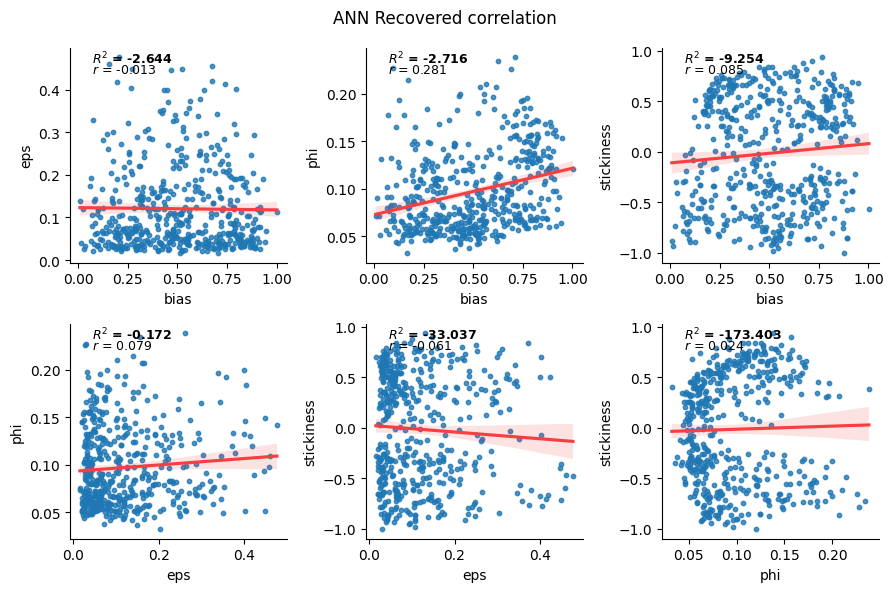

In [ ]:
import math

n_col = len(params)*(len(params)-1)//2
params = sorted(params)
n_row = 2
n_col = math.ceil(n_col/n_row)
fig, axes = plt.subplots(n_row, n_col, figsize=(3*n_col, 3*n_row))
ai = 0
flatted_axes = axes.flatten()
for i, pn1 in enumerate(params):
    for j, pn2 in enumerate(params[i+1:]):
        y_true, y_pred = result[f'dl_{pn1}'], result[f'dl_{pn2}']
        ax = flatted_axes[ai]
        sns.regplot(x=y_true, y=y_pred, ax=ax, line_kws=dict(color="#f73e40"), scatter_kws=dict(s=10))
        ax = add_corr_scores(ax, y_true, y_pred)
        ax.set_xlabel(pn1)
        ax.set_ylabel(pn2)
        ai += 1

sns.despine()
fig.suptitle('ANN Recovered correlation')
fig.tight_layout()

## Hyperparameters finetuning

In [ ]:
# setup
!pip install --upgrade keras-hypetune
!pip install -q -U keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 966.0/966.0 kB 24.7 MB/s eta 0:00:00
  Attempting uninstall: hyperopt
    Found existing installation: hyperopt 0.2.7
    Uninstalling hyperopt-0.2.7:
      Successfully uninstalled hyperopt-0.2.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.9 MB/s eta 0:00:00


In [ ]:
from kerashypetune import KerasBayesianSearch
from hyperopt import hp, Trials


model_func = get_gru_model
param_grid = {
  'feature_dim': train_features.shape[-1],
  'output_dims': normalized_train_labels.shape[-1],
  'units': hp.choice('units', [96, 128, 512]),
  'learning_rate': hp.loguniform('learning_rate', np.log(3e-4), np.log(3e-3)),
  'dropout': hp.uniform('dropout', .015, .25),
  'dropout1': hp.uniform('dropout1', .01, .2),
  'dropout2': hp.uniform('dropout2', .01, .2),
  'epochs': 35,
  'batch_size': hp.choice('batch_size', [128, 256, 512]),
}

kbs = KerasBayesianSearch(
    model_func, param_grid, monitor='val_loss', greater_is_better=False, n_iter=10, sampling_seed=11)
callbacks = [EarlyStopping(monitor='val_loss', patience=35)]

kbs.search(
  x=train_features,
  y=normalized_train_labels,
  trials=Trials(),
  validation_data=(val_features, normalized_val_labels),
  callbacks=callbacks,
)
print(kbs.best_params)
print(kbs.scores)


10 trials detected for ('feature_dim', 'output_dims', 'units', 'learning_rate', 'dropout', 'dropout1', 'dropout2', 'epochs', 'batch_size')

***** (1/10) *****
Search({'batch_size': 256, 'dropout': 0.18957980398908159, 'dropout1': 0.15459304402984714, 'dropout2': 0.024492309835077653, 'epochs': 35, 'feature_dim': 6, 'learning_rate': 0.0008172615018876134, 'output_dims': 4, 'units': 512})
SCORE: 0.40167 at epoch 35

***** (2/10) *****
Search({'batch_size': 512, 'dropout': 0.04746658505561911, 'dropout1': 0.029667931981551425, 'dropout2': 0.10064162199618662, 'epochs': 35, 'feature_dim': 6, 'learning_rate': 0.0003769355442896412, 'output_dims': 4, 'units': 128})
SCORE: 0.74402 at epoch 34

***** (3/10) *****
Search({'batch_size': 128, 'dropout': 0.05469810926102504, 'dropout1': 0.03270538551855236, 'dropout2': 0.020741906361950876, 'epochs': 35, 'feature_dim': 6, 'learning_rate': 0.002494216656437813, 'output_dims': 4, 'units': 512})
SCORE: 0.24846 at epoch 20

***** (4/10) *****
Search(

KeyboardInterrupt: 

In [ ]:
from kerashypetune import KerasGridSearch


param_grid = {
    'feature_dim': train_features.shape[-1],
    'output_dims': normalized_train_labels.shape[-1],
    'units': 128,
    'dropout': [0.2, 0.1],
    'dropout1': [0.1, 0.05],
    'dropout2': [0.01, 0.05],
    'learning_rate': 0.002,
    'epochs': 35,
    'batch_size': 128,
}

kgs = KerasGridSearch(get_gru_model, param_grid, monitor='val_loss', greater_is_better=False)
callbacks = [EarlyStopping(monitor='val_loss', patience=15)]
kgs.search(train_features, normalized_train_labels, validation_data=(val_features, normalized_val_labels), callbacks=callbacks)
print(kgs.best_params)
print(kgs.scores)